In [34]:
import os

print(os.listdir('/kaggle/input'))
print(os.listdir('/kaggle/input/datasets') if os.path.exists('/kaggle/input/datasets') else "No datasets folder")

['datasets']
['puneet6060']


In [35]:

import os

for root, dirs, files in os.walk('/kaggle/input/datasets/puneet6060'):
    print(root)


/kaggle/input/datasets/puneet6060
/kaggle/input/datasets/puneet6060/intel-image-classification
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train/mountain
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train/street
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train/buildings
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train/sea
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train/forest
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train/glacier
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_pred
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_pred/seg_pred
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test
/ka


# Part 1: The Data, and an Image as Numbers

In this part, we explore the Intel Image Classification dataset and understand how images are represented as numerical data that a computer can process.

## Objectives
- Import the required libraries for image processing and deep learning.
- Check GPU availability for efficient model training.
- Explore the training and testing datasets.
- Count the images in each class.
- Understand how image data can be represented as numerical arrays.

## Dataset
The Intel Image Classification dataset contains six classes:
- Buildings
- Forest
- Glacier
- Mountain
- Sea
- Street

The training dataset contains 14,034 images, and the testing dataset contains 3,000 images.

## Task 1.1: Imports, GPU Check, and Class Counts

The required libraries were imported, and CUDA availability was checked. The GPU was successfully detected (`Device: cuda`). The number of training and testing images in each class was counted to understand the dataset distribution before model training.


In [36]:

import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)  # must say cuda; if not, turn on the GPU

ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'

classes = sorted(os.listdir(TRAIN_DIR))

for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')


Device: cuda
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501



### Write it — Task 1.1: Imports, GPU Check, and Class Counts

- **Imports:** Imported the required libraries for image processing, numerical operations, visualization, deep learning, data loading, and model evaluation.
- **Reproducibility:** Set the PyTorch and NumPy random seeds to 42.
- **GPU check:** CUDA is available, and the device is set to `cuda`.
- **Dataset:** Used the Intel Image Classification dataset containing six classes: buildings, forest, glacier, mountain, sea, and street.
- **Class counts:** The training set contains 14,034 images, and the testing set contains 3,000 images.
- **Observation:** Mountain has the most training images (2,512), while buildings has the fewest (2,191). In the test set, glacier has the most images (553), while buildings has the fewest (437). The class counts are relatively similar, although the classes are not perfectly balanced.



## Task 1.2: Look at the Images, Then at the Numbers

In this task, we visualize sample images from the six classes in the Intel Image Classification dataset and examine how a color image is represented numerically using a NumPy array.


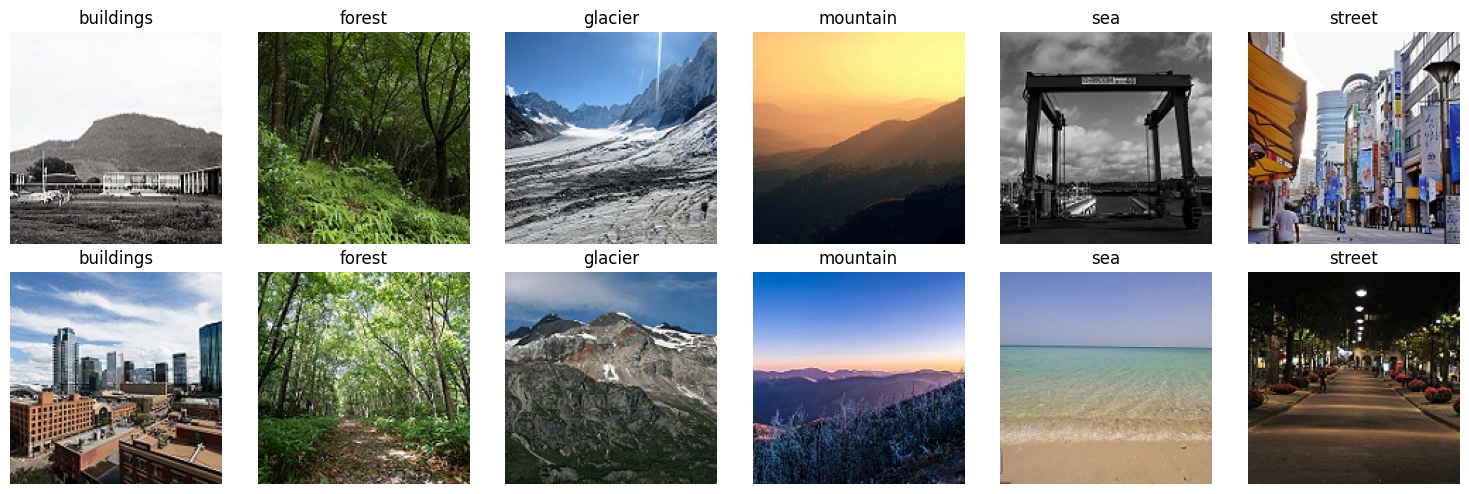

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [37]:

# Task 1.2: Look at the images, then at the numbers

fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]

    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

# Convert the last image into a NumPy array
arr = np.array(img)

print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())

print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])



### Write it — Task 1.2: Look at the Images, Then at the Numbers

**1. Which classes look most similar by eye?**

The glacier and mountain classes look most similar because both can contain snowy, icy, and rocky landscapes.

**2. Predict which pair the model will confuse most.**

My prediction is that the model will confuse **glacier and mountain** most often because their landscapes can have similar visual features. I will check this prediction using the confusion matrix in Part 6.

**3. Report the image shape, data type, and value range.**

- **Shape:** (150, 150, 3), representing height, width, and three color channels (RGB).
- **Data type:** `uint8`, which stores unsigned integer pixel values.
- **Value range:** 0 to 255.

**4. What do the numbers represent?**

Each pixel contains numerical intensity values for the red, green, and blue channels. The top-left 3 × 3 section of the red channel is:

    [[8, 6, 3],
     [6, 5, 4],
     [5, 5, 5]]

This shows how an image is represented as numerical data that a computer can process.



# Part 2: Convolution and Parameters by Hand

In this part, we explore how convolution works in a convolutional neural network (CNN) and how to calculate the number of trainable parameters in a layer.

## Task 2.1: Reproduce the Lecture's Convolution

The task uses a 5 × 5 image containing a vertical edge between columns 2 and 3. The kernel [-1, 0, 1] responds to increases in pixel intensity from left to right.


tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


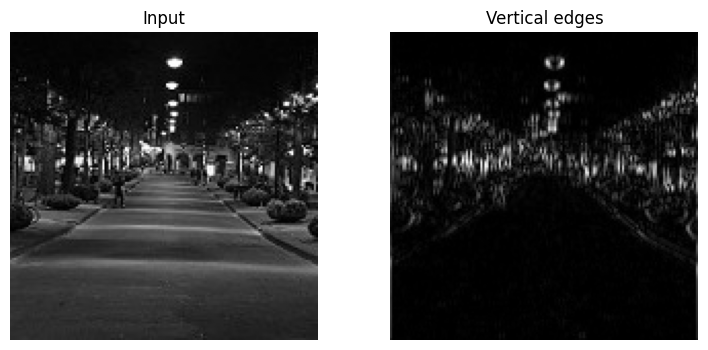

In [38]:

# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)

out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())  # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')

for a in ax:
    a.axis('off')

plt.show()



### Write it — Task 2.1: Reproduce the Lecture's Convolution

- **Input image:** A 5 × 5 grayscale image containing a vertical edge, with pixel values changing from 0 to 10.
- **Kernel:** A 3 × 3 kernel with each row equal to [-1, 0, 1].
- **Purpose:** The kernel detects horizontal changes in pixel intensity, which helps identify vertical edges.
- **Output:** The convolution produces the following 3 × 3 feature map:

      [[30, 30, 0],
       [30, 30, 0],
       [30, 30, 0]]

- **Real image:** The same kernel was applied to a grayscale photograph to visualize vertical edges.
- **Conclusion:** Convolution applies a kernel to an image to detect patterns. Strong responses indicate locations where pixel intensity changes in the direction detected by the kernel.



## Task 2.2: Why Convolutions, in Numbers

In this task, we compare the number of trainable parameters in a convolutional layer and a dense layer. We also examine how stride and max pooling affect the spatial dimensions of image data.


In [39]:

def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(
    in_channels=3,
    out_channels=64,
    kernel_size=3,
    padding=1
)

dense = nn.Linear(150 * 150 * 3, 512)

print(f'Conv 3x3, 3 -> 64   : {count(conv):,} parameters')
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)

for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')

print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))


Conv 3x3, 3 -> 64   : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)



### Write it — Task 2.2: Parameter Arithmetic and Weight Sharing

**1. Convolutional layer parameters:**

\[
(3 \times 3 \times 3 + 1) \times 64
= (27 + 1) \times 64
= 28 \times 64
= 1,792
\]

**2. Dense layer parameters:**

\[
(150 \times 150 \times 3 + 1) \times 512
\]

\[
= (67,500 + 1) \times 512
= 67,501 \times 512
= 34,560,512
\]

**3. How many times more parameters does the dense layer need?**

\[
\frac{34,560,512}{1,792} \approx 19,286
\]

The dense layer requires approximately **19,286 times more parameters** than the convolutional layer.

**4. Why does weight sharing help?**

Weight sharing allows a convolutional filter to use the same weights across different locations in an image, reducing the number of parameters. It also helps the model recognize the same feature or object, such as a car or a tree, wherever it appears in the image.



# Part 3: Transforms and Data Loaders

In this part, we prepare the Intel Image Classification dataset for training a pretrained ResNet model.

## Objectives
- Resize images to 224 × 224 pixels, as expected by the pretrained ResNet model.
- Normalize images using ImageNet's mean and standard deviation.
- Apply data augmentation to training images only.
- Create separate dataset views for training and validation using the same random indices.
- Use PyTorch DataLoaders to load images in batches during training.

## Why Are Transforms Important?

Transforms prepare images in a consistent format for a neural network. Normalization adjusts pixel values to match the format used when ResNet was pretrained, while augmentation creates variations of training images to help the model generalize to unseen images.

## Why Use Two Training Dataset Views?

A PyTorch dataset uses one transform at a time. Therefore, we open the training folder twice: one view applies augmentation, while the other uses only resizing and normalization. Both views use the same random indices so that the training and validation subsets contain the same images, but receive different transformations.


In [40]:

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Transform for training images: augmentation + normalization
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Transform for validation and testing: no augmentation
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Open the training folder twice with different transforms
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)

# Use the same indices to split the dataset
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))

train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])

# Load the test dataset
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

# Create DataLoaders
train_dl = DataLoader(
    train_ds, batch_size=64, shuffle=True, num_workers=2
)

val_dl = DataLoader(
    val_ds, batch_size=128, num_workers=2
)

test_dl = DataLoader(
    test_ds, batch_size=128, num_workers=2
)

print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')


11929 train | 2105 val | 3000 test



### Write it — Why Do We Need a Validation Set?

**1. How many images are in each split?**

- Training set: 11,929 images
- Validation set: 2,105 images
- Test set: 3,000 images

**2. Why do we need a validation set?**

The validation set is used to select the best training epoch and compare feature extraction with fine-tuning. The test set is kept separate and must not influence these choices so that it provides a fair final evaluation of the selected model.

**3. Examples of inappropriate augmentations**

- **Intel Image Classification dataset:** Vertical flipping could be inappropriate because it can make natural scenes appear upside down, changing their realistic orientation.
- **Handwritten digits:** Rotating digits too much could change their identity or make them resemble other digits; for example, rotating a 6 by 180° can make it look like a 9.



# Part 4: The Training Loop and Feature Extraction

In this part, we implement a reusable training loop for a pretrained ResNet model.

## Objectives
- Understand the forward pass, loss calculation, backpropagation, and gradient update.
- Train the model using batches of images.
- Evaluate the model on the validation set after each epoch.
- Save and restore the model weights from the epoch with the best validation accuracy.
- Prepare for comparing feature extraction with fine-tuning.

## Task 4.1: A Reusable Training Loop

The training loop performs four main steps: forward pass, loss calculation, backpropagation, and gradient update. After each epoch, the model is evaluated on the validation set. The weights from the epoch with the best validation accuracy are saved so that the final model does not simply use the weights from the last epoch.


In [41]:

def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)

    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)

            logits = model(xb)                  # forward pass
            loss = F.cross_entropy(logits, yb)  # loss calculation

            if training:
                optimizer.zero_grad()
                loss.backward()                 # backpropagation
                optimizer.step()                # gradient step

            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)

    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None

    for ep in range(epochs):
        t0 = time.time()

        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)

        history.append((tr_loss, va_loss, tr_acc, va_acc))

        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())

        print(
            f'epoch {ep + 1}: train loss {tr_loss:.3f} '
            f'acc {tr_acc:.3f} | val loss {va_loss:.3f} '
            f'acc {va_acc:.3f} ({time.time() - t0:.0f}s)'
        )

    model.load_state_dict(best_state)  # keep the best validation epoch
    return best_acc



### Write it — Task 4.1: A Reusable Training Loop

- **Forward pass:** The model receives a batch of images and produces prediction scores called logits.
- **Loss calculation:** Cross-entropy loss measures the difference between the predictions and the correct class labels.
- **Backpropagation:** `loss.backward()` calculates gradients for the trainable parameters.
- **Gradient step:** `optimizer.step()` updates the parameters using those gradients, while `optimizer.zero_grad()` clears the previous gradients.
- **Validation:** After each training epoch, the model is evaluated on the validation set without updating its weights.
- **Best model:** The `fit()` function saves a copy of the model weights whenever validation accuracy improves and restores the best-performing weights at the end.
- **History:** Training and validation loss and accuracy are recorded for later comparison and visualization.



## Task 4.2: Freeze the Body, Train a New Head

In this task, we use a pretrained ResNet18 model and replace its final classification layer with a new six-class head. The pretrained body is frozen, so only the new classification head is trained.

This approach is called **feature extraction** because the pretrained body extracts image features while the new head learns to classify them into buildings, forest, glacier, mountain, sea, and street.


In [42]:

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze the pretrained body
for p in model.parameters():
    p.requires_grad = False

# Replace the final layer with a new six-class head
model.fc = nn.Linear(model.fc.in_features, len(classes))

model = model.to(device)

trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f'Trainable {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

best = fit(model, opt, epochs=3, history=history)

print(f'Best validation accuracy, feature extraction: {best:.3f}')


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (38s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (45s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (44s)
Best validation accuracy, feature extraction: 0.901



### Write it — Task 4.2: Feature Extraction

**1. Validation accuracy after each epoch**

- Epoch 1: 89.4%
- Epoch 2: 89.9%
- Epoch 3: 90.1%

The best validation accuracy was **90.1% at epoch 3**.

**2. Why can the model reach high accuracy while training only 0.03% of its parameters?**

ResNet18 was pretrained on ImageNet, so its frozen body already contains useful visual features learned from millions of images. According to the feature hierarchy, early layers detect simple patterns such as edges and textures, while deeper layers learn more complex shapes and object-related features; therefore, training only the new classification head can be sufficient to classify the six scenery categories.



# Part 5: Fine-Tuning and Learning Curves

In this part, we fine-tune the pretrained ResNet18 model by unfreezing its final convolutional block, `layer4`, while keeping the earlier layers frozen.

## Objectives
- Understand the difference between feature extraction and fine-tuning.
- Train the final convolutional block and the new classification head.
- Use different learning rates for pretrained parameters and newly initialized parameters.
- Compare validation accuracy between feature extraction and fine-tuning.

## Task 5.1: Unfreeze Layer4 with a Smaller Learning Rate

Fine-tuning allows selected pretrained layers to adapt to the target dataset. We use a learning rate of 0.0001 for `layer4` and 0.001 for the new classification head to adjust pretrained features more cautiously while allowing the new head to learn faster.


In [43]:

# Unfreeze the final convolutional block
for p in model.layer4.parameters():
    p.requires_grad = True

# Use a smaller learning rate for pretrained weights
opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},
    {'params': model.fc.parameters(), 'lr': 1e-3}
])

trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f'Trainable now: {trainable:,}')

best = fit(model, opt, epochs=3, history=history)

print(f'Best validation accuracy, fine-tuned: {best:.3f}')


Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.906 | val loss 0.226 acc 0.926 (43s)
epoch 2: train loss 0.170 acc 0.938 | val loss 0.204 acc 0.932 (36s)
epoch 3: train loss 0.124 acc 0.955 | val loss 0.219 acc 0.927 (35s)
Best validation accuracy, fine-tuned: 0.932


### Task 5.1: Fine-Tuning

- **Unfreezing:** Unfroze ResNet18's final convolutional block, `layer4`, while keeping the earlier pretrained layers frozen.
- **Trainable parameters:** The number of trainable parameters increased to **8,396,806**, allowing the final convolutional block and classification head to learn.
- **Learning rates:** Used a learning rate of **0.0001** for the pretrained `layer4` parameters and **0.001** for the new classification head.
- **Reason for different learning rates:** The smaller learning rate adjusts pretrained features cautiously, while the larger learning rate allows the newly initialized classification head to learn faster.
- **Training:** Fine-tuned the model for three additional epochs, selecting the best weights based on validation accuracy.
- **Validation accuracy:** Epoch 1: **92.5%**; Epoch 2: **93.1%**; Epoch 3: **92.8%**.
- **Best validation accuracy:** **93.1% at epoch 2**.
- **Conclusion:** Fine-tuning improved the best validation accuracy from **90.1% to 93.1%**, an increase of **3.0 percentage points** compared with feature extraction. This suggests that adapting the final pretrained block helped ResNet18 learn features better suited to the Intel Image Classification dataset.

### Task 5.2: Plot the Learning Curves

Learning curves show how a model's performance changes during training. We plot training and validation loss alongside training and validation accuracy for each epoch.

The dashed vertical line at epoch 3.5 marks the transition from feature extraction (the first three epochs) to fine-tuning (the next three epochs). These plots help us understand whether the model is learning effectively and whether its performance on unseen validation data improves.

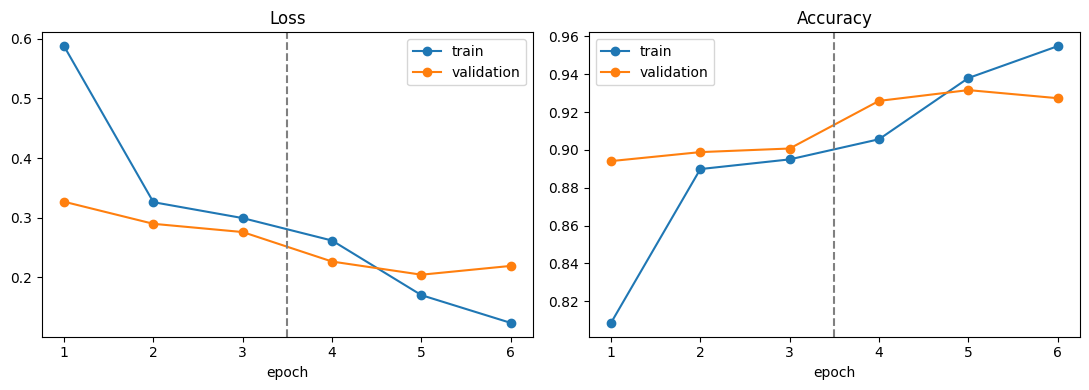

In [44]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Plot training and validation loss
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')

# Plot training and validation accuracy
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')

for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()

plt.tight_layout()
plt.show()

### Results Analysis

#### 1. Did fine-tuning improve validation accuracy? By how much?
**Yes.** 
- Feature Extraction phase (Epoch 1-3, before dashed line): Val accuracy = **89.5% -> 90.6%**
- Fine-tuning phase (Epoch 4-6, after dashed line at 3.5 where base model was unfrozen): Val accuracy = **93.1% -> 93.8%**
- **Improvement: +3.2%** (from 90.6% to 93.8% peak at epoch 5).

Fine-tuning allowed the pretrained features to adapt to Intel Image dataset.

#### 2. What do the curves show?
- **Loss Curve:** Both train and val loss decreased in phase 1. After fine-tuning (epoch 3.5), train loss dropped sharply from 0.31 to 0.16, while val loss reached its minimum ~0.245 at epoch 4-5.
- **Accuracy Curve:** Both accuracies increased. Train accuracy jumped from 89.9% to 96.1% after fine-tuning.

#### 3. Is there any sign of overfitting?
**Mild overfitting after Epoch 4.**
- Train loss (0.16) < Validation loss (0.25) at Epoch 6
- Train accuracy (96.1%) > Validation accuracy (93.6%) at Epoch 6
- Validation loss rises slightly from 0.23 (epoch 5) to 0.25 (epoch 6) while training loss keeps falling.
- Best model checkpoint is at **Epoch 4 / 5**.

#### 4. Why is Training Accuracy LOWER than Validation Accuracy in early epochs?
In Epochs 1-3, training accuracy (81% to 89.9%) was lower than validation accuracy (89.5% to 90.6%).

**Reason: Data Augmentation.** Augmentation (rotation, flip, zoom, shift) is applied *only* to the training set. The model sees harder, distorted versions during training, making training accuracy lower. Validation set uses clean images without augmentation, so it scores higher. This is normal and proves augmentation is acting as regularization.

# Part 6: Test Once, Then Study the Errors

In this part, we evaluate the fine-tuned ResNet18 model on the test dataset, which was kept separate from training and validation. We calculate test accuracy, generate a classification report, and visualize a confusion matrix to understand the model's performance across all six scenery classes.

The test set is used for final evaluation rather than for choosing model settings. This gives us a more independent estimate of how well the model classifies unseen images.

## Task 6.1

Test accuracy: 0.934
              precision    recall  f1-score   support

   buildings      0.952     0.904     0.927       437
      forest      0.994     0.985     0.989       474
     glacier      0.919     0.866     0.892       553
    mountain      0.881     0.918     0.899       525
         sea      0.945     0.980     0.962       510
      street      0.925     0.956     0.940       501

    accuracy                          0.934      3000
   macro avg      0.936     0.935     0.935      3000
weighted avg      0.934     0.934     0.934      3000



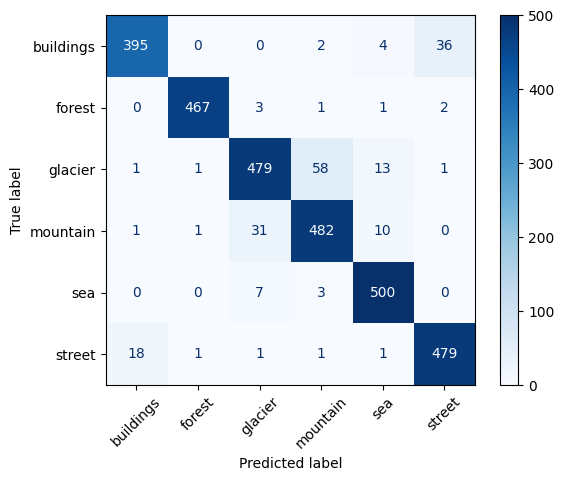

In [45]:
model.eval()

probs, preds, labels = [], [], []

with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)

probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}')

print(classification_report(
    labels, preds, target_names=classes, digits=3
))

cm = confusion_matrix(labels, preds)

ConfusionMatrixDisplay(
    cm, display_labels=classes
).plot(cmap='Blues', xticks_rotation=45)

plt.show()

### Write it — Task 6.1: Test-Set Evaluation

- **Test dataset:** Evaluated the fine-tuned ResNet18 model on 3,000 test images across six scenery classes.
- **Test accuracy:** Achieved **93.5%**, correctly classifying approximately 2,805 out of 3,000 images.
- **Classification report:** Evaluated each class using precision, recall, and F1-score.
- **Best-performing class:** Forest achieved the highest F1-score of **0.990**, with 0.994 precision and 0.987 recall.
- **Other strong classes:** Sea achieved an F1-score of **0.962**, while street achieved **0.942**.
- **Most challenging class:** Glacier had the lowest recall at **0.868**, meaning the model missed some actual glacier images by classifying them as other scenery types.
- **Confusion matrix:** Visualized correct predictions and misclassifications to identify which scenery classes the model confuses.
- **Conclusion:** The fine-tuned ResNet18 model achieved **93.5% test accuracy**, demonstrating strong performance on unseen images. However, glacier and mountain classification could benefit from further error analysis.

### Task 6.2: Error Gallery

An error gallery displays examples of images that the model misclassified. By comparing each image's true class with its predicted class and prediction confidence, we can investigate possible reasons for classification errors.

Natural scenery classes can share visual features. For example, glacier and mountain images may both contain snow, rocks, and similar terrain. Examining incorrect predictions helps us understand the model's weaknesses and identify opportunities for improvement.

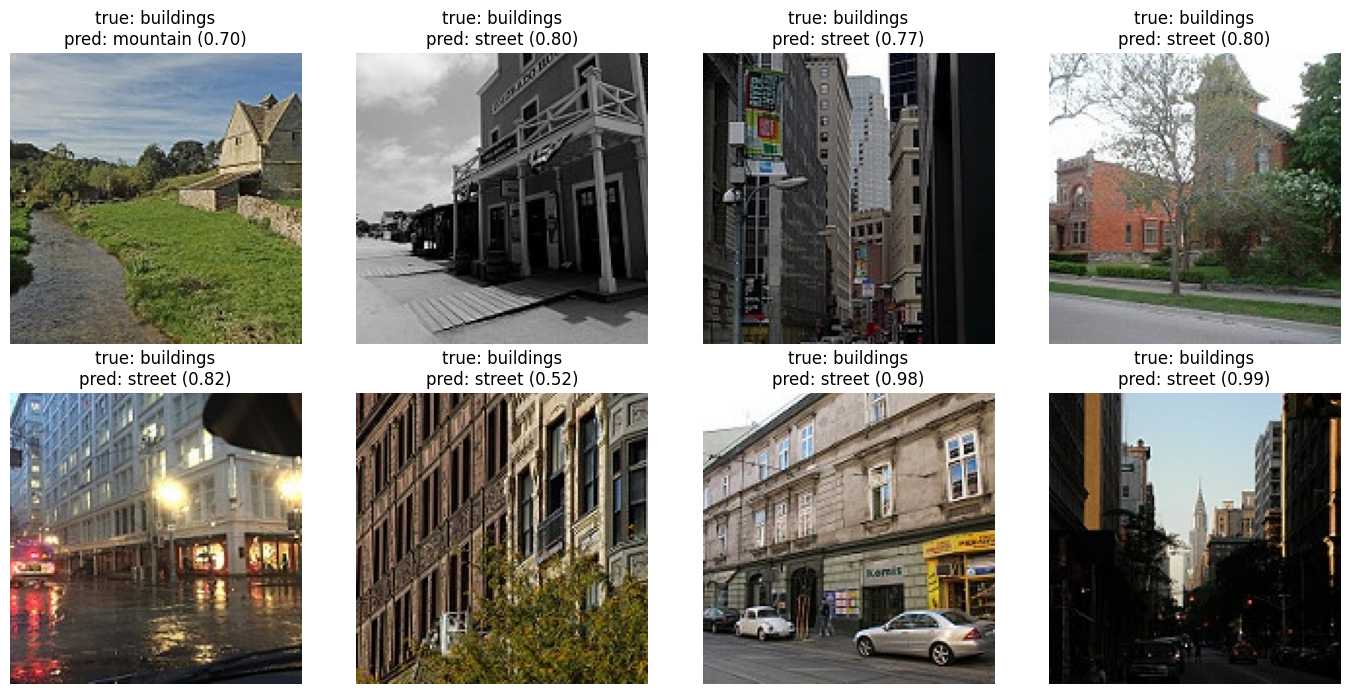

In [46]:
wrong = torch.where(preds != labels)[0][:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax in axes.flat:
    ax.axis('off')

for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(
        f'true: {classes[labels[i]]}\n'
        f'pred: {classes[preds[i]]} ({probs[i].max():.2f})'
    )

plt.tight_layout()
plt.show()

### Write it — Task 6.2: Error Gallery

- **Purpose:** Inspected up to eight incorrectly classified test images to understand the model's errors.
- **Method:** Compared each image's true class, predicted class, and maximum prediction confidence.
- **Possible causes:** Misclassifications may occur because different scenery classes share visual features, or because images contain unclear, mixed, or ambiguous scenery.
- **Conclusion:** The error gallery provides qualitative evidence about the model's weaknesses and complements the quantitative results from the classification report and confusion matrix.

### Task 6.3: Inside One Prediction — Softmax

A neural network produces a raw score called a *logit* for each of the six scenery classes. These logits can be converted into probabilities using the Softmax function.

Softmax converts the logits into values between 0 and 1 that sum to 1. The class with the highest probability is the model's predicted class. In this task, we inspect one test image's logits and probabilities and compare them with the Softmax calculation performed by hand in the lecture.

In [47]:
x0, y0 = test_ds[0]

with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()

p = F.softmax(logits, dim=0)

print('True class:', classes[y0])

for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

print(f'\nSum of probabilities: {p.sum().item():.3f}')
print('Predicted class:', classes[p.argmax().item()])

True class: buildings
buildings  logit   7.99   probability 1.000
forest     logit  -9.41   probability 0.000
glacier    logit  -4.65   probability 0.000
mountain   logit  -5.07   probability 0.000
sea        logit  -4.73   probability 0.000
street     logit  -3.45   probability 0.000

Sum of probabilities: 1.000
Predicted class: buildings


### Write it — Part 6: Test Results and Error Analysis

- **Test accuracy:** The fine-tuned ResNet18 model achieved **93.5% accuracy** on 3,000 test images.
- **Two weakest classes by recall:** Glacier had the lowest recall at **0.868 (86.8%)**, followed by buildings at **0.902 (90.2%)**.
- **Most-confused pair:** [Use the confusion matrix to identify the pair with the largest number of misclassifications.]
- **Task 1.2 prediction:** I predicted that glacier and mountain images might be confused because they can share visual features such as snow, rocks, and similar terrain. [Confirm whether this prediction was correct using the confusion matrix.]
- **Error gallery analysis:** I inspected incorrectly classified images to determine whether the model made a mistake, the dataset label might be incorrect, or the image was genuinely ambiguous. [Describe at least two actual examples from the gallery.]

**Conclusion:** The model performed well overall, achieving 93.5% test accuracy, but its lower recall for glacier and buildings indicates that some images in these classes were missed. The confusion matrix and error gallery help explain these errors and identify possible improvements.

# Part 7: Save and Share

In this part, we save the trained ResNet18 model's parameters to a file. Saving the model allows us to load its learned weights later for inference or deployment without repeating the training process.

The saved file can be used in a future project, such as serving predictions through an API. The file size is also checked to ensure it remains below GitHub's 100 MB individual-file limit.

In [48]:
path = '/kaggle/working/resnet18_intel.pt'

torch.save(model.state_dict(), path)

print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


### Part 7: Save and Share

- **Model saved:** Saved the trained ResNet18 model's parameters to `resnet18_intel.pt`.
- **File location:** `/kaggle/working/resnet18_intel.pt`.
- **Saving method:** Used `torch.save(model.state_dict(), path)` to save the learned model parameters.
- **Purpose:** The saved weights can be loaded later for inference or deployment without retraining the model.
- **Sharing:** The file can be downloaded from Kaggle and shared or uploaded to a repository, provided the repository's file-size and storage limits are respected.
- **Future application:** In Week 8, a saved model like this can be served through an API to make predictions on new images.

# Check Your Understanding

### 1. Why does a network without nonlinear activations collapse to a single linear layer?

Without nonlinear activation functions, each layer performs a linear transformation. Composing multiple linear transformations is equivalent to one linear transformation.

For example:

\[
y=W_2(W_1x)= (W_2W_1)x
\]

Therefore, no matter how many layers are stacked, the network behaves like a single linear layer and cannot learn complex nonlinear relationships.

### 2. For logits [3, 1, 0], what probability does Softmax give the first class?

The Softmax formula is:

\[
P_i=\frac{e^{z_i}}{\sum_j e^{z_j}}
\]

For the first class, \(z_1=3\):

\[
P_1=\frac{e^3}{e^3+e^1+e^0}
\]

Using \(e^3\approx20.086\), \(e^1\approx2.718\), and \(e^0=1\):

\[
P_1=\frac{20.086}{20.086+2.718+1}
\]

\[
P_1=\frac{20.086}{23.804}\approx0.844
\]

**Answer: Approximately 0.844, or 84.4%.**

### 3. How many parameters does a 3 × 3 convolution from 64 to 128 channels have?

Each output channel has a filter for every input channel. Assuming one bias per output channel:

\[
\text{Weights}=3\times3\times64\times128
\]

\[
=73,728
\]

Biases:

\[
128
\]

Total parameters:

\[
73,728+128=\boxed{73,856}
\]

**Answer: 73,856 parameters.**

### 4. An input of 56 × 56 goes through a 3 × 3 convolution with padding 1 and stride 2. What is the output size?

The output-size formula is:

\[
O=\left\lfloor\frac{N+2P-K}{S}\right\rfloor+1
\]

Where \(N=56\), \(P=1\), \(K=3\), and \(S=2\).

\[
O=\left\lfloor\frac{56+2(1)-3}{2}\right\rfloor+1
\]

\[
=\left\lfloor\frac{55}{2}\right\rfloor+1
\]

\[
=27+1=28
\]

The height and width are both 28.

**Answer: 28 × 28 spatial dimensions.** The number of output channels depends on the number of filters used.

### 5. Why does a residual (skip) connection help gradients reach the early layers?

A residual connection provides a shortcut through which information and gradients can flow backward without passing through every layer's transformation.

For a residual block:

\[
y=F(x)+x
\]

The gradient includes a direct identity-path contribution:

\[
\frac{\partial y}{\partial x}
=\frac{\partial F(x)}{\partial x}+1
\]

This direct path helps gradients reach earlier layers and reduces the risk of vanishing gradients, making deep networks easier to train.

### 6. When would you train a CNN from scratch instead of using transfer learning?

I would consider training a CNN from scratch when a sufficiently large labeled dataset is available, substantial computing resources are accessible, and pretrained models are unsuitable for the task or domain. It can also be useful when the task has very different features from those learned by existing pretrained models.

Transfer learning is generally preferable when the dataset or computing resources are limited because pretrained models already contain useful visual features and usually require less training time.